In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt

try:
    import scienceplots
    plt.style.use(['science', 'no-latex', 'ieee'])
except ModuleNotFoundError:
    pass

plt.rc('axes', labelsize=14)
plt.rcParams['axes.titlesize'] = 20
plt.rc('xtick', labelsize=14)
plt.rc('ytick', labelsize=14)
plt.rc('legend', fontsize=10)
plt.rc('lines', linewidth=2)


# Keep the notebook independent of the original machine-specific src path.
# The current metric analysis uses only arrays already stored in the HDF5 files.


/opt/software-current/2023.06/x86_64/intel/skylake_avx512/software/Python-bundle-PyPI/2023.06-GCCcore-12.3.0/lib/python3.11/site-packages/pyparsing/core.py:5596: SyntaxWarning: 'return' in a 'finally' block
  return self.__class__.__name__ + ": " + retString


In [2]:
def percentile_bands(samples, levels=(0.68, 0.95)):
    out = {}
    for lev in levels:
        lo = 100 * (0.5 - lev / 2.0)
        hi = 100 * (0.5 + lev / 2.0)
        out[f"lower_{int(round(100*lev))}"] = np.percentile(samples, lo, axis=0)
        out[f"upper_{int(round(100*lev))}"] = np.percentile(samples, hi, axis=0)
    return out


def crps_from_samples(y_true, y_samps):
    """
    Empirical-sample CRPS at each point.

    y_true  : (N,)
    y_samps : (S, N)
    returns : (N,)
    """
    y_true = np.asarray(y_true, dtype=float)
    y_samps = np.asarray(y_samps, dtype=float)

    term1 = np.mean(np.abs(y_samps - y_true[None, :]), axis=0)
    pairwise = np.abs(y_samps[:, None, :] - y_samps[None, :, :])
    term2 = 0.5 * np.mean(pairwise, axis=(0, 1))
    return term1 - term2


def kl_gaussian_exp_vs_samples(y_true, y_err, y_samps, eps=1e-12):
    """
    Per-point KL divergence D_KL(P_exp || Q_pred), where

      P_exp  = N(y_true, y_err^2)
      Q_pred ~= N(mean(samples), std(samples)^2)

    y_true : (N,)
    y_err  : (N,)
    y_samps: (S, N)

    returns: (N,)
    """
    y_true = np.asarray(y_true, dtype=float)
    y_err = np.asarray(y_err, dtype=float)
    y_samps = np.asarray(y_samps, dtype=float)

    mu_q = np.mean(y_samps, axis=0)
    std_q = np.std(y_samps, axis=0, ddof=1)

    std_p = np.maximum(y_err, eps)
    std_q = np.maximum(std_q, eps)

    kl = np.log(std_q / std_p) + (
        std_p**2 + (y_true - mu_q)**2
    ) / (2.0 * std_q**2) - 0.5

    return kl


def reduced_chi2(y_true, y_pred_mean, y_err, dof_correction=0, eps=1e-12):
    y_err = np.maximum(np.asarray(y_err, dtype=float), eps)
    resid = (np.asarray(y_true) - np.asarray(y_pred_mean)) / y_err
    nu = max(len(y_true) - dof_correction, 1)
    return np.sum(resid**2) / nu


def nlpd_gaussian_from_samples(y_true, y_err, y_samps, eps=1e-12):
    """
    Pointwise NLPD using Gaussian approximation to predictive samples and
    adding experimental variance in quadrature:

      y_obs ~ N(mu_pred, std_pred^2 + y_err^2)
    """
    y_true = np.asarray(y_true, dtype=float)
    y_err = np.asarray(y_err, dtype=float)
    y_samps = np.asarray(y_samps, dtype=float)

    mu = np.mean(y_samps, axis=0)
    std_pred = np.std(y_samps, axis=0, ddof=1)
    var_tot = np.maximum(std_pred**2 + y_err**2, eps)

    nlpd = 0.5 * np.log(2.0 * np.pi * var_tot) + 0.5 * (y_true - mu)**2 / var_tot
    return nlpd


def coverage95_error_from_samples(y_true, y_samps):
    """
    Returns per-point 0/1 coverage indicator converted later to a score.
    """
    lo = np.percentile(y_samps, 2.5, axis=0)
    hi = np.percentile(y_samps, 97.5, axis=0)
    covered = ((y_true >= lo) & (y_true <= hi)).astype(float)
    return covered


def make_energy_weights(E):
    """
    Quadrature-like normalized weights on experimental energies.
    """
    E = np.asarray(E, dtype=float)
    N = len(E)
    if N == 1:
        return np.array([1.0])

    w = np.zeros(N, dtype=float)
    w[0] = 0.5 * (E[1] - E[0])
    w[-1] = 0.5 * (E[-1] - E[-2])
    for i in range(1, N - 1):
        w[i] = 0.5 * (E[i + 1] - E[i - 1])

    w = np.maximum(w, 0.0)
    s = np.sum(w)
    if s <= 0:
        return np.ones(N) / N
    return w / s


def safe_log_transform(y, y_err=None, y_samps=None, eps=1e-12):
    """
    log transform for positive sigma-like quantities.
    y_err is propagated with sigma_log ~= sigma_y / y.
    """
    y = np.asarray(y, dtype=float)
    y_clip = np.maximum(y, eps)
    logy = np.log(y_clip)

    out = [logy]

    if y_err is not None:
        y_err = np.asarray(y_err, dtype=float)
        logy_err = y_err / y_clip
        out.append(logy_err)

    if y_samps is not None:
        y_samps = np.asarray(y_samps, dtype=float)
        logy_samps = np.log(np.maximum(y_samps, eps))
        out.append(logy_samps)

    return tuple(out)


def weighted_mean(vals, w):
    vals = np.asarray(vals, dtype=float)
    w = np.asarray(w, dtype=float)
    return np.sum(w * vals)


def compute_metric_bundle(E_data, Sigma_data, Sigma_err, y_samples_at_data):
    """
    Returns scalar metrics for a single run.
    Lower is better for every returned metric.
    """
    metrics = {}

    y_mean_at_data = np.mean(y_samples_at_data, axis=0)
    Ew = make_energy_weights(E_data)

    metrics["redchi2_sigma"] = reduced_chi2(
        Sigma_data, y_mean_at_data, Sigma_err, dof_correction=0
    )

    nlpd_vals = nlpd_gaussian_from_samples(Sigma_data, Sigma_err, y_samples_at_data)
    metrics["nlpd_sigma"] = np.nanmean(nlpd_vals)

    crps_vals = crps_from_samples(Sigma_data, y_samples_at_data)
    metrics["crps_sigma"] = np.nanmean(crps_vals)

    cov95_vals = coverage95_error_from_samples(Sigma_data, y_samples_at_data)
    metrics["cov95_sigma"] = abs(np.nanmean(cov95_vals) - 0.95)

    kl_vals = kl_gaussian_exp_vs_samples(Sigma_data, Sigma_err, y_samples_at_data)
    metrics["kl_sigma"] = np.nanmean(kl_vals)

    chi2_pointwise = ((Sigma_data - y_mean_at_data) / np.maximum(Sigma_err, 1e-12))**2
    metrics["redchi2_sigma_Ew"] = weighted_mean(chi2_pointwise, Ew)

    metrics["nlpd_sigma_Ew"] = weighted_mean(nlpd_vals, Ew)
    metrics["crps_sigma_Ew"] = weighted_mean(crps_vals, Ew)
    metrics["cov95_sigma_Ew"] = abs(weighted_mean(cov95_vals, Ew) - 0.95)
    metrics["kl_sigma_Ew"] = weighted_mean(kl_vals, Ew)

    logy, logy_err, logy_samps = safe_log_transform(
        Sigma_data, y_err=Sigma_err, y_samps=y_samples_at_data
    )
    logy_mean = np.mean(logy_samps, axis=0)

    metrics["redchi2_log"] = reduced_chi2(
        logy, logy_mean, logy_err, dof_correction=0
    )

    nlpd_log_vals = nlpd_gaussian_from_samples(logy, logy_err, logy_samps)
    metrics["nlpd_log"] = np.nanmean(nlpd_log_vals)

    crps_log_vals = crps_from_samples(logy, logy_samps)
    metrics["crps_log"] = np.nanmean(crps_log_vals)

    cov95_log_vals = coverage95_error_from_samples(logy, logy_samps)
    metrics["cov95_log"] = abs(np.nanmean(cov95_log_vals) - 0.95)

    kl_log_vals = kl_gaussian_exp_vs_samples(logy, logy_err, logy_samps)
    metrics["kl_log"] = np.nanmean(kl_log_vals)

    return metrics


# BNN Model-Selection Metrics

The goal of this notebook is to ask whether any scalar scoring rule is a useful model-selection heuristic for AutoBNN barrier extraction. We start with controlled Wong-formula toy data, where the true barrier is known and the scoring rules can be checked directly against barrier error. We then apply the same style of scoring to the experimental D3 sweep, where there is no exact ground truth but the metrics still expose how the candidate fits behave.

The working hypothesis is deliberately skeptical: a good scoring rule may not strongly correlate with choosing the visually or physically better barrier model. The cells below keep that question empirical.


## Wong Toy Data: 10-Rep Model-Selection Checks

This section was moved from `BNNDataAnalysis.ipynb`, beginning at its “New 10-rep model-selection results” section. Each model/dataset pair has 10 independent runs. Because these are Wong-formula toy datasets, the CSV files provide true-barrier metrics such as barrier MAE and empirical-coverage error. We use those as the target outcomes and test whether loss, prediction-only proxies, or the scoring rules defined above would have selected the better run.


In [3]:
# Summarize the 10-rep D3-lambda=1e1 Wong toy runs.
PROJECT_ROOT = Path("/mnt/home/philipaa/research/barrier-extraction")
PLOT_DIR = PROJECT_ROOT / "plots"
PLOT_DIR.mkdir(exist_ok=True)

BNN_D3LAM1E1_10REP_RESULTS = Path(
    "/mnt/home/philipaa/scratch/barrier-paper-results/bnn_data_analysis_models_d3lam1e1_10reps"
)
BNN_D3LAM1E1_10REP_PREFIX = "bnn_data_analysis_4curves"
BNN_D3LAM1E1_10REP_SUFFIX = "bnn_d3lam1e1_10reps"
COVERAGE_LEVELS = np.array([0.0, 0.25, 0.50, 0.68, 0.90, 0.95, 1.0])
COVERAGE_COLUMNS = [
    "barrier_emp_cov_0",
    "barrier_emp_cov_25",
    "barrier_emp_cov_50",
    "barrier_emp_cov_68",
    "barrier_emp_cov_90",
    "barrier_emp_cov_95",
    "barrier_emp_cov_100",
]

MODEL_SPECS = [
    ("Changepoint of Safe Products", "changepoint_of_safe_products"),
    ("Sum of Changepoints", "sum_of_changepoints"),
    ("Sum of Products", "sum_of_products"),
    ("Sum of Stumps", "sum_of_stumps"),
]

BNN_10REP_CASE_SPECS = [
    ("E_20_1e-1_log", rf"$\eta = 10^{{-1}}$", "noise_ratio"),
    ("E_20_1e-2_log", rf"$\eta = 10^{{-2}}$", "noise_ratio"),
    ("E_cv_05_log", rf"$\langle\Delta E\rangle = 0.50\,\mathrm{{MeV}}$", "irregularity_spacing"),
    ("E_cv_05_1MEV_log", rf"$\langle\Delta E\rangle = 1.00\,\mathrm{{MeV}}$", "irregularity_spacing"),
]
BNN_10REP_CASE_LABELS = {case_slug: label for case_slug, label, _ in BNN_10REP_CASE_SPECS}

TOY_SCORE_COLS = [
    "redchi2_sigma",
    "nlpd_sigma",
    "crps_sigma",
    "cov95_sigma",
    "kl_sigma",
    "redchi2_log",
    "nlpd_log",
    "crps_log",
    "cov95_log",
    "kl_log",
    "redchi2_sigma_Ew",
    "nlpd_sigma_Ew",
    "crps_sigma_Ew",
    "cov95_sigma_Ew",
    "kl_sigma_Ew",
]


def _only_h5_group(h5_file):
    return next(iter(h5_file.values()))


def bnn_d3lam1e1_10rep_part_dir(case_slug, model_slug):
    dirname = f"{BNN_D3LAM1E1_10REP_PREFIX}_{case_slug}_{model_slug}_{BNN_D3LAM1E1_10REP_SUFFIX}.h5.parts"
    return BNN_D3LAM1E1_10REP_RESULTS / dirname


def run_from_part_path(path):
    return int(path.stem.rsplit("_run", 1)[1])


def lowest_total_train_loss(h5_path):
    with h5py.File(h5_path, "r") as f:
        group = _only_h5_group(f)
        total_loss = group["base_loss_samples"][()] + group["d3_penalty_loss_samples"][()]
    return float(np.nanmin(total_loss))


def wong_sigma(E, E0, R0, hbarw):
    return 10.0 * (0.5 * R0**2 * hbarw / E) * np.log(
        1.0 + np.exp(2.0 * np.pi * (E - E0) / hbarw)
    )


def barrier_from_sigma(E, sigma_values):
    return np.gradient(np.gradient(E * sigma_values, E, edge_order=2), E, edge_order=2)


def true_barrier_from_group(group, x_pred):
    attrs = dict(group.attrs)
    E0 = float(attrs.get("E0_true", attrs.get("params_true_E0")))
    R0 = float(attrs.get("R0_true", attrs.get("params_true_R0")))
    hw = float(attrs.get("hw_true", attrs.get("params_true_hw")))
    return barrier_from_sigma(x_pred, wong_sigma(x_pred, E0, R0, hw))


def _empirical_coverage_mae_at_training(y_true, y_samples, levels=COVERAGE_LEVELS):
    coverages = []
    for level in levels:
        lower = np.percentile(y_samples, (1 - level) / 2 * 100, axis=0)
        upper = np.percentile(y_samples, (1 + level) / 2 * 100, axis=0)
        coverages.append(np.mean((y_true >= lower) & (y_true <= upper)))
    return float(np.mean(np.abs(np.asarray(coverages) - levels)))


def _prediction_only_proxy_metrics(group):
    E_train = group["E_data"][()]
    sigma_train = group["Sigma_data"][()]
    x_pred = group["x_pred"][()]
    y_samples = group["y_samples"][()]
    d2_samples = group["d2_samples"][()]

    train_samples = np.vstack([np.interp(E_train, x_pred, sample) for sample in y_samples])
    log_train = np.log(np.maximum(sigma_train, 1e-30))
    log_train_samples = np.log(np.maximum(train_samples, 1e-30))

    d_mean = np.nanmean(d2_samples, axis=0)
    d_low, d_high = np.nanpercentile(d2_samples, [2.5, 97.5], axis=0)
    dx = float(np.median(np.diff(x_pred)))
    tail = x_pred > 80.0
    if not np.any(tail):
        tail = np.ones_like(x_pred, dtype=bool)

    return {
        "proxy_barrier_abs_mean": float(np.nanmean(np.abs(d_mean))),
        "proxy_barrier_tail_abs_mean": float(np.nanmean(np.abs(d_mean[tail]))),
        "proxy_barrier_total_variation": float(np.nansum(np.abs(np.diff(d_mean))) / max(np.ptp(x_pred), 1e-12)),
        "proxy_barrier_mean_abs_slope": float(np.nanmean(np.abs(np.diff(d_mean) / dx))),
        "proxy_barrier_band_width_mean": float(np.nanmean(d_high - d_low)),
        "proxy_train_log_ec_mae": _empirical_coverage_mae_at_training(log_train, log_train_samples),
    }


In [4]:
def load_bnn_10rep_metric_table():
    rows = []
    missing = []
    for case_slug, case_label, figure_group in BNN_10REP_CASE_SPECS:
        for model_name, model_slug in MODEL_SPECS:
            part_dir = bnn_d3lam1e1_10rep_part_dir(case_slug, model_slug)
            for csv_path in sorted(part_dir.glob("*.csv")):
                run = run_from_part_path(csv_path)
                h5_path = csv_path.with_suffix(".h5")
                if not h5_path.exists():
                    missing.append(str(h5_path))
                    continue

                csv_metrics = pd.read_csv(csv_path).iloc[0].to_dict()
                empirical_coverages = np.array([csv_metrics[col] for col in COVERAGE_COLUMNS], dtype=float)

                with h5py.File(h5_path, "r") as f:
                    group = _only_h5_group(f)
                    x_pred = group["x_pred"][()]
                    y_samples = group["y_samples"][()]
                    E_data = group["E_data"][()]
                    Sigma_data = group["Sigma_data"][()]
                    Sigma_err = group["Sigma_err"][()]
                    y_samples_at_data = np.vstack([
                        np.interp(E_data, x_pred, sample) for sample in y_samples
                    ])
                    score_metrics = compute_metric_bundle(
                        E_data=E_data,
                        Sigma_data=Sigma_data,
                        Sigma_err=Sigma_err,
                        y_samples_at_data=y_samples_at_data,
                    )
                    proxy_metrics = _prediction_only_proxy_metrics(group)

                rows.append({
                    "case_slug": case_slug,
                    "case_label": case_label,
                    "figure_group": figure_group,
                    "model": model_name,
                    "model_slug": model_slug,
                    "run": run,
                    "h5_path": str(h5_path),
                    "csv_path": str(csv_path),
                    "min_total_train_loss": lowest_total_train_loss(h5_path),
                    "barrier_MAE": float(csv_metrics["barrier_MAE"]),
                    "barrier_emp_cov_MAE": float(np.mean(np.abs(empirical_coverages - COVERAGE_LEVELS))),
                    **csv_metrics,
                    **score_metrics,
                    **proxy_metrics,
                })

    if missing:
        print(f"Missing {len(missing)} HDF5 files; first missing path: {missing[0]}")
    return pd.DataFrame(rows).sort_values(["case_slug", "model", "run"]).reset_index(drop=True)


bnn_10rep_metrics = load_bnn_10rep_metric_table()
bnn_10rep_metrics.to_csv(PLOT_DIR / "bnn_d3lam1e1_10rep_selection_metrics_with_scores.csv", index=False)

print(f"Loaded {len(bnn_10rep_metrics)} runs across {bnn_10rep_metrics['case_slug'].nunique()} toy cases")
print(bnn_10rep_metrics[["case_slug", "model", "run", "min_total_train_loss", "barrier_MAE", "barrier_emp_cov_MAE"]].head())


Loaded 160 runs across 4 toy cases
       case_slug                         model  run  min_total_train_loss  \
0  E_20_1e-1_log  Changepoint of Safe Products    0           2824.194843   
1  E_20_1e-1_log  Changepoint of Safe Products    1           2830.366987   
2  E_20_1e-1_log  Changepoint of Safe Products    2           2817.618722   
3  E_20_1e-1_log  Changepoint of Safe Products    3           2825.039686   
4  E_20_1e-1_log  Changepoint of Safe Products    4           2817.239506   

   barrier_MAE  barrier_emp_cov_MAE  
0    82.070060             0.088267  
1    79.335095             0.088267  
2   101.706215             0.038723  
3   119.168439             0.033860  
4   146.194419             0.061520  


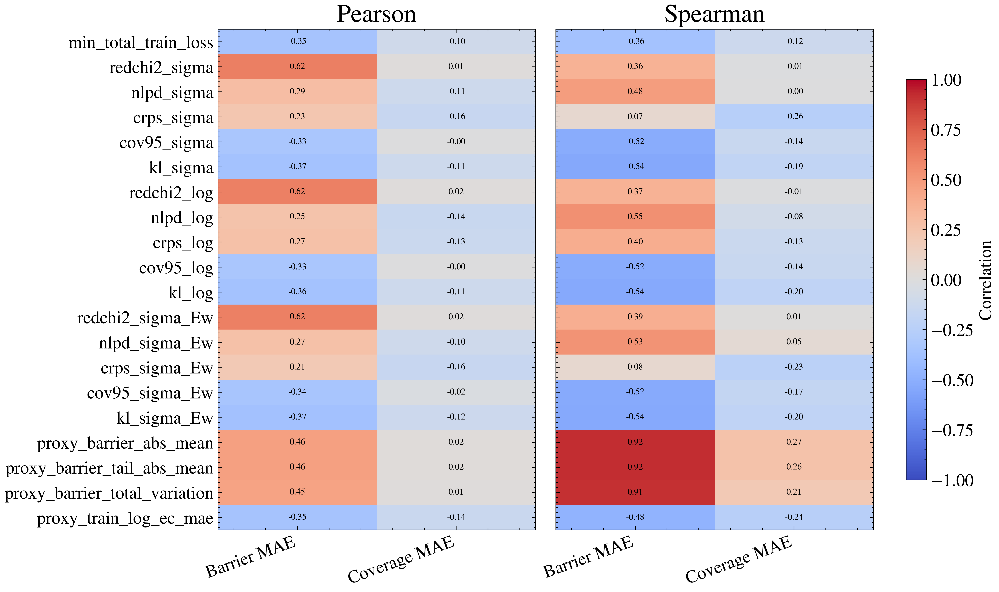

                        score      target   pearson  spearman
       proxy_barrier_abs_mean barrier_MAE  0.462417  0.920175
  proxy_barrier_tail_abs_mean barrier_MAE  0.462459  0.918628
proxy_barrier_total_variation barrier_MAE  0.446262  0.913477
                     nlpd_log barrier_MAE  0.250769  0.546818
                     kl_sigma barrier_MAE -0.365592 -0.541641
                  kl_sigma_Ew barrier_MAE -0.367482 -0.536971
                       kl_log barrier_MAE -0.363781 -0.536233
                nlpd_sigma_Ew barrier_MAE  0.271136  0.525349
               cov95_sigma_Ew barrier_MAE -0.340864 -0.523996
                  cov95_sigma barrier_MAE -0.328826 -0.517905
                    cov95_log barrier_MAE -0.328826 -0.517905
                   nlpd_sigma barrier_MAE  0.289169  0.477212


In [5]:
def _correlation_text(x, y):
    pearson = x.corr(y, method="pearson")
    spearman = x.corr(y, method="spearman")
    return f"Pearson r = {pearson:.2f}; Spearman rho = {spearman:.2f}"


SCORING_HEURISTICS = [
    "min_total_train_loss",
    "redchi2_sigma",
    "nlpd_sigma",
    "crps_sigma",
    "cov95_sigma",
    "kl_sigma",
    "redchi2_log",
    "nlpd_log",
    "crps_log",
    "cov95_log",
    "kl_log",
    "redchi2_sigma_Ew",
    "nlpd_sigma_Ew",
    "crps_sigma_Ew",
    "cov95_sigma_Ew",
    "kl_sigma_Ew",
    "proxy_barrier_abs_mean",
    "proxy_barrier_tail_abs_mean",
    "proxy_barrier_total_variation",
    "proxy_train_log_ec_mae",
]
TARGET_METRICS = ["barrier_MAE", "barrier_emp_cov_MAE"]

corr_rows = []
for score in SCORING_HEURISTICS:
    for target in TARGET_METRICS:
        corr_rows.append({
            "score": score,
            "target": target,
            "pearson": bnn_10rep_metrics[score].corr(bnn_10rep_metrics[target], method="pearson"),
            "spearman": bnn_10rep_metrics[score].corr(bnn_10rep_metrics[target], method="spearman"),
        })
score_correlation_df = pd.DataFrame(corr_rows)
score_correlation_df.to_csv(PLOT_DIR / "bnn_d3lam1e1_10rep_score_correlations.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 6.5), constrained_layout=True)
for ax, method in zip(axes, ["pearson", "spearman"]):
    heat = score_correlation_df.pivot(index="score", columns="target", values=method).loc[SCORING_HEURISTICS]
    im = ax.imshow(heat.values, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
    ax.set_title(method.capitalize())
    ax.set_xticks(np.arange(len(heat.columns)))
    ax.set_xticklabels(["Barrier MAE", "Coverage MAE"], rotation=20, ha="right")
    ax.set_yticks(np.arange(len(heat.index)))
    ax.set_yticklabels(heat.index if ax is axes[0] else [])
    for i in range(heat.shape[0]):
        for j in range(heat.shape[1]):
            ax.text(j, i, f"{heat.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=axes, shrink=0.8, label="Correlation")
#fig.suptitle("Toy-data scoring-rule correlations with true barrier outcomes")
fig.savefig(PLOT_DIR / "bnn_d3lam1e1_10rep_score_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

top_score_correlations = (
    score_correlation_df.assign(abs_spearman=score_correlation_df["spearman"].abs())
    .sort_values(["target", "abs_spearman"], ascending=[True, False])
)
print(top_score_correlations.head(12).drop(columns="abs_spearman").to_string(index=False))


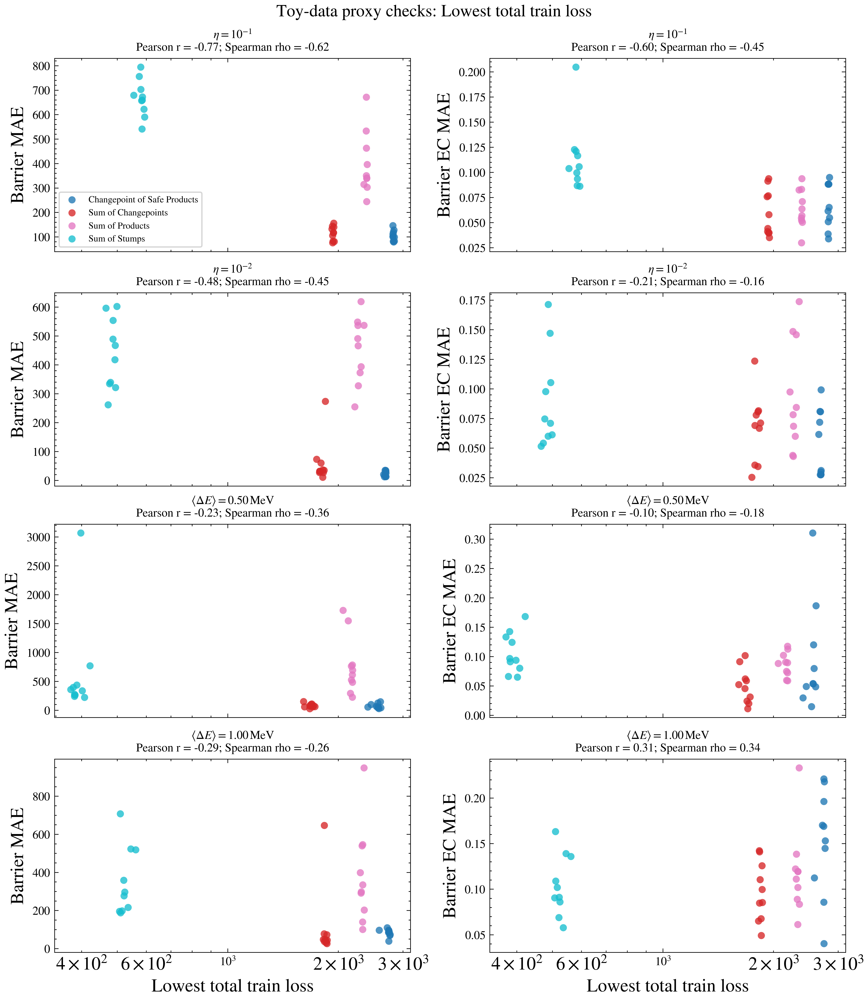

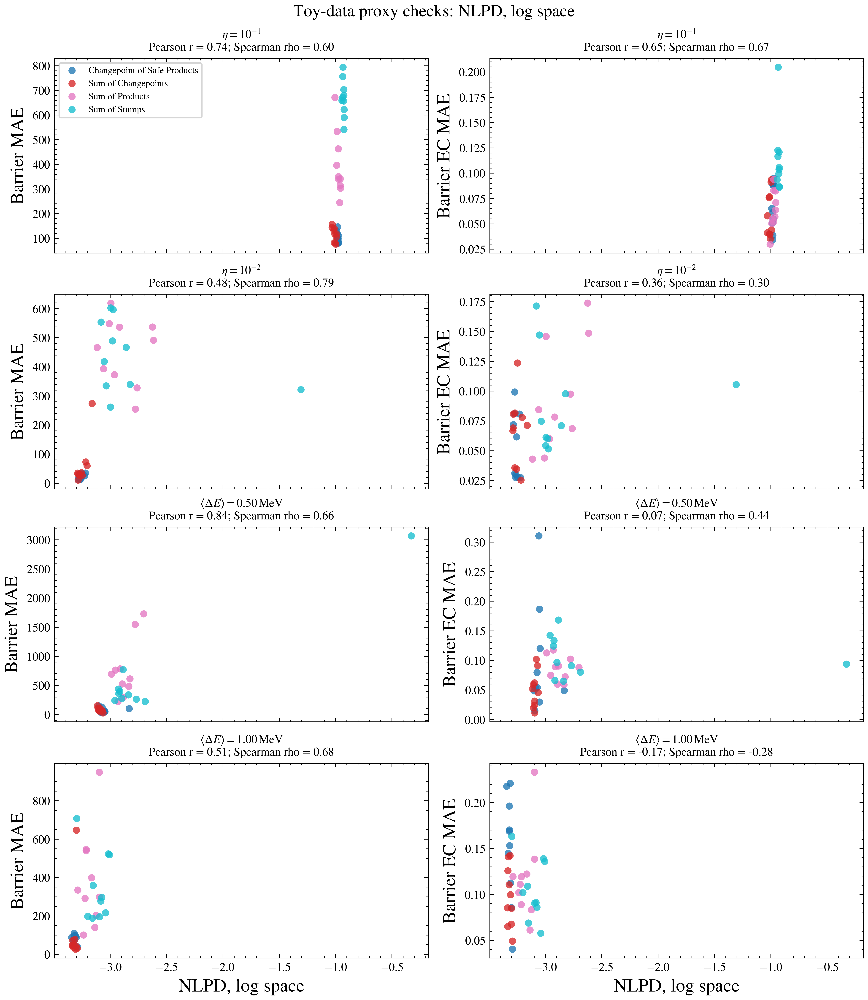

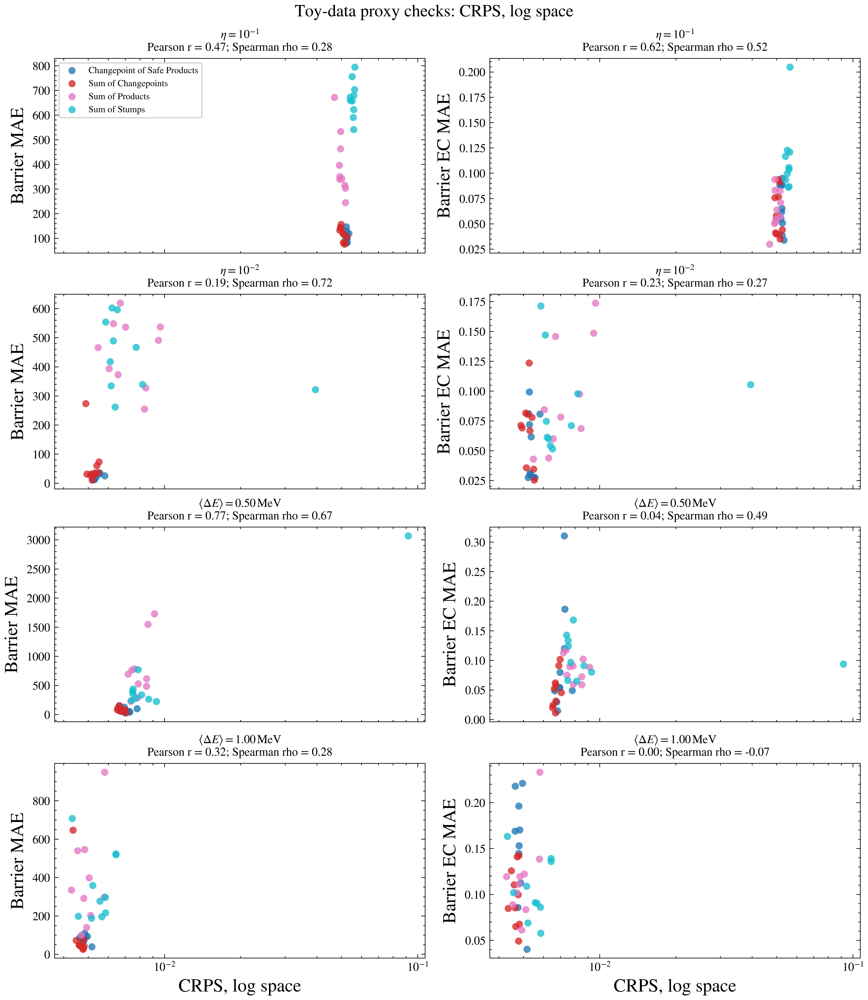

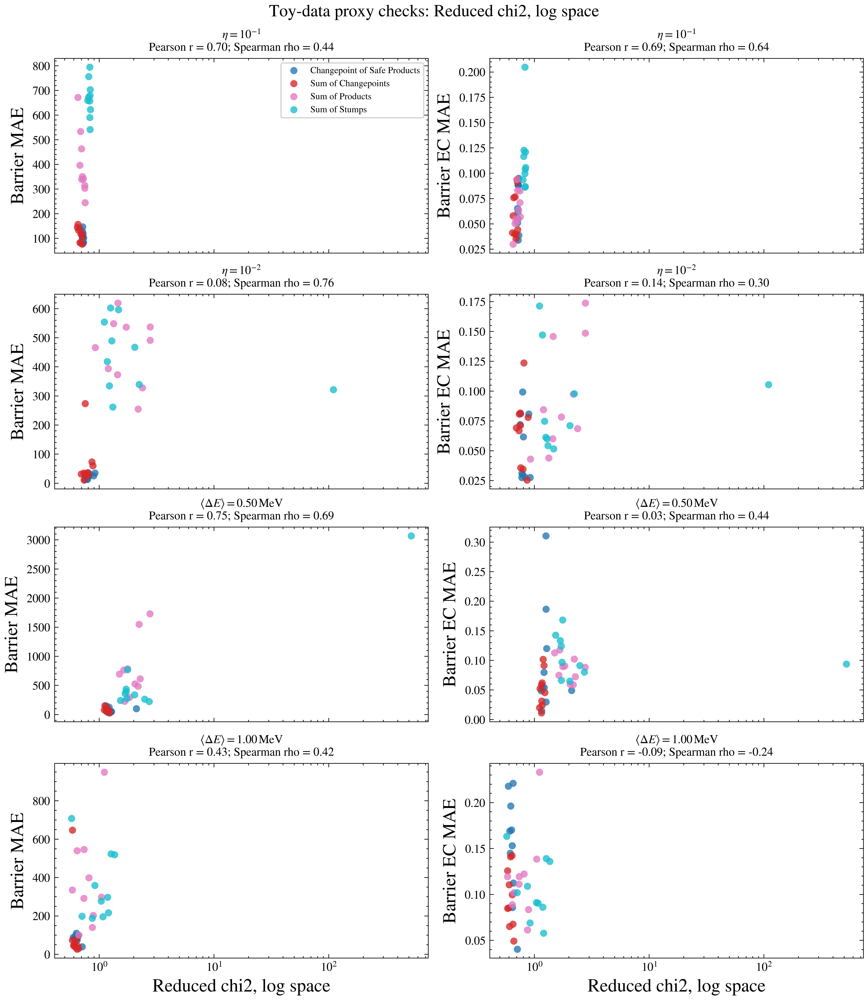

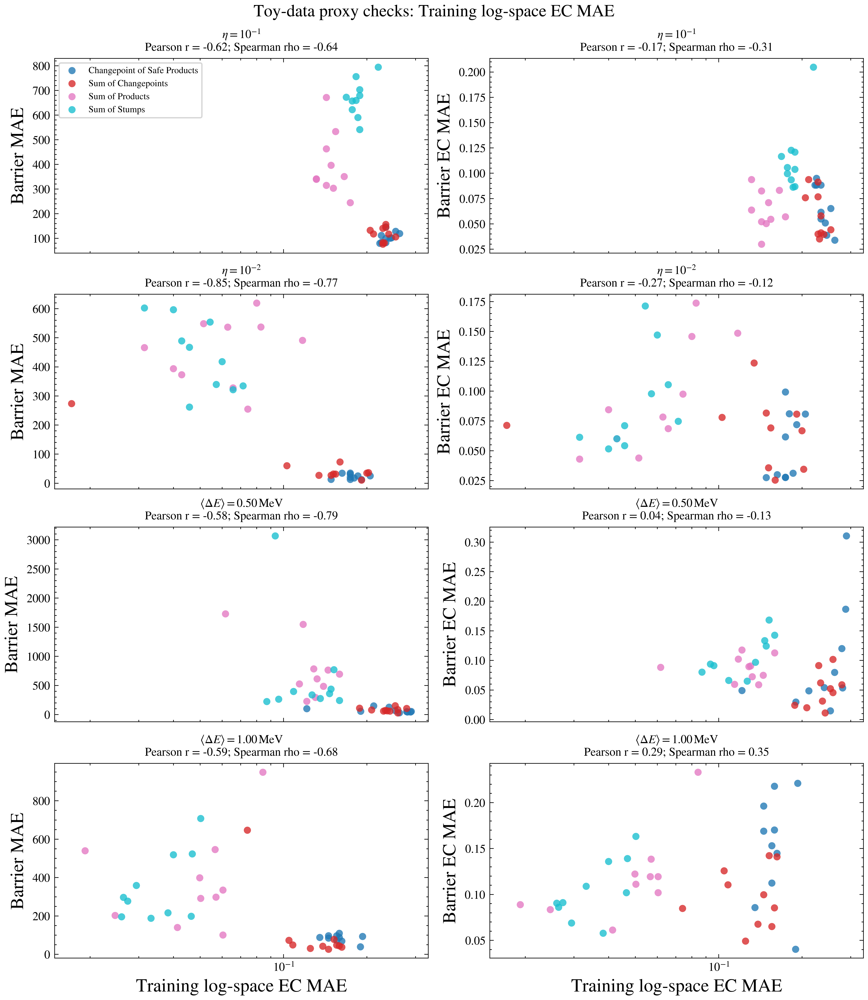

In [6]:
model_colors = dict(zip([name for name, _ in MODEL_SPECS], plt.cm.tab10(np.linspace(0, 1, len(MODEL_SPECS)))))

SCATTER_SCORE_SPECS = [
    ("min_total_train_loss", "Lowest total train loss", "train_loss"),
    ("nlpd_log", "NLPD, log space", "nlpd_log"),
    ("crps_log", "CRPS, log space", "crps_log"),
    ("redchi2_log", "Reduced chi2, log space", "redchi2_log"),
    ("proxy_train_log_ec_mae", "Training log-space EC MAE", "train_log_ec_mae"),
]


def plot_score_scatter_grid(score_column, score_label, filename_stub):
    fig, axes = plt.subplots(
        len(BNN_10REP_CASE_SPECS),
        2,
        figsize=(9.2, 10.6),
        sharex="col",
        constrained_layout=True,
    )
    for row, (case_slug, case_label, _) in enumerate(BNN_10REP_CASE_SPECS):
        case_metrics = bnn_10rep_metrics[bnn_10rep_metrics["case_slug"] == case_slug]
        for model_name, group in case_metrics.groupby("model"):
            axes[row, 0].scatter(
                group[score_column],
                group["barrier_MAE"],
                s=30,
                alpha=0.78,
                color=model_colors[model_name],
                edgecolor="none",
                label=model_name,
            )
            axes[row, 1].scatter(
                group[score_column],
                group["barrier_emp_cov_MAE"],
                s=30,
                alpha=0.78,
                color=model_colors[model_name],
                edgecolor="none",
            )

        axes[row, 0].set_title(
            f"{case_label}\n" + _correlation_text(case_metrics[score_column], case_metrics["barrier_MAE"]),
            fontsize=9,
        )
        axes[row, 1].set_title(
            f"{case_label}\n" + _correlation_text(case_metrics[score_column], case_metrics["barrier_emp_cov_MAE"]),
            fontsize=9,
        )
        axes[row, 0].set_ylabel("Barrier MAE")
        axes[row, 1].set_ylabel("Barrier EC MAE")

    positive_score = np.all(np.asarray(bnn_10rep_metrics[score_column], dtype=float) > 0)
    for ax in axes.flat:
        if positive_score:
            ax.set_xscale("log")
        ax.tick_params(labelsize=9)
    for ax in axes[-1, :]:
        ax.set_xlabel(score_label)
    axes[0, 0].legend(loc="best", fontsize=7, frameon=True)
    fig.suptitle(f"Toy-data proxy checks: {score_label}", fontsize=13)
    fig.savefig(PLOT_DIR / f"bnn_d3lam1e1_10rep_score_scatter_{filename_stub}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


for score_column, score_label, filename_stub in SCATTER_SCORE_SPECS:
    plot_score_scatter_grid(score_column, score_label, filename_stub)


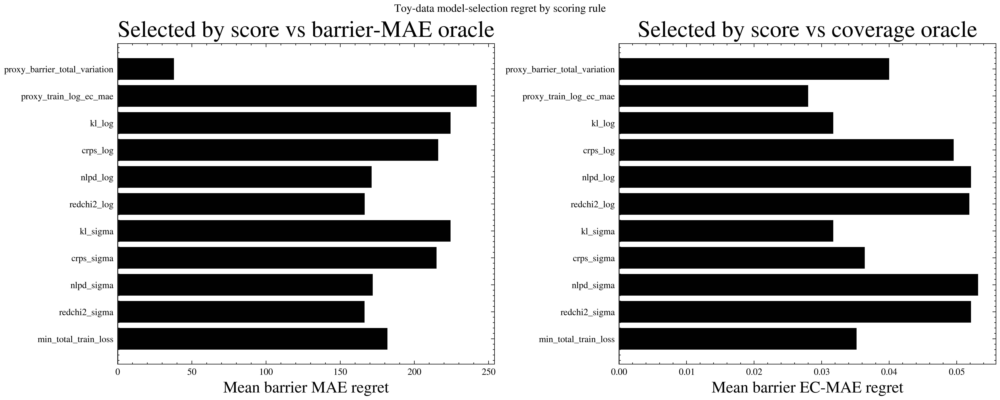

                     selector  mean_barrier_MAE  mean_barrier_emp_cov_MAE  mean_selected_run  barrier_MAE_regret_vs_oracle  barrier_EC_MAE_regret_vs_oracle
           oracle_barrier_MAE        146.234494                  0.081324             3.9375                      0.000000                         0.038168
proxy_barrier_total_variation        184.237951                  0.083151             4.5000                     38.003457                         0.039995
        oracle_barrier_EC_MAE        248.975109                  0.043156             5.0000                    102.740615                         0.000000
                redchi2_sigma        312.618921                  0.095275             5.0625                    166.384427                         0.052119
                  redchi2_log        312.686556                  0.095028             5.0000                    166.452062                         0.051872
                     nlpd_log        317.415922                 

In [7]:
def summarize_selection_by_score(score_columns):
    rows = []
    group_cols = ["case_slug", "model"]
    oracle_mae_idx = bnn_10rep_metrics.groupby(group_cols)["barrier_MAE"].idxmin()
    oracle_ec_idx = bnn_10rep_metrics.groupby(group_cols)["barrier_emp_cov_MAE"].idxmin()
    rows.append({
        "selector": "oracle_barrier_MAE",
        "mean_barrier_MAE": bnn_10rep_metrics.loc[oracle_mae_idx, "barrier_MAE"].mean(),
        "mean_barrier_emp_cov_MAE": bnn_10rep_metrics.loc[oracle_mae_idx, "barrier_emp_cov_MAE"].mean(),
        "mean_selected_run": bnn_10rep_metrics.loc[oracle_mae_idx, "run"].mean(),
    })
    rows.append({
        "selector": "oracle_barrier_EC_MAE",
        "mean_barrier_MAE": bnn_10rep_metrics.loc[oracle_ec_idx, "barrier_MAE"].mean(),
        "mean_barrier_emp_cov_MAE": bnn_10rep_metrics.loc[oracle_ec_idx, "barrier_emp_cov_MAE"].mean(),
        "mean_selected_run": bnn_10rep_metrics.loc[oracle_ec_idx, "run"].mean(),
    })
    for score in score_columns:
        idx = bnn_10rep_metrics.groupby(group_cols)[score].idxmin()
        chosen = bnn_10rep_metrics.loc[idx]
        rows.append({
            "selector": score,
            "mean_barrier_MAE": chosen["barrier_MAE"].mean(),
            "mean_barrier_emp_cov_MAE": chosen["barrier_emp_cov_MAE"].mean(),
            "mean_selected_run": chosen["run"].mean(),
        })
    out = pd.DataFrame(rows)
    out["barrier_MAE_regret_vs_oracle"] = out["mean_barrier_MAE"] - out.loc[out["selector"] == "oracle_barrier_MAE", "mean_barrier_MAE"].iloc[0]
    out["barrier_EC_MAE_regret_vs_oracle"] = out["mean_barrier_emp_cov_MAE"] - out.loc[out["selector"] == "oracle_barrier_EC_MAE", "mean_barrier_emp_cov_MAE"].iloc[0]
    return out


selection_score_cols = [
    "min_total_train_loss",
    "redchi2_sigma",
    "nlpd_sigma",
    "crps_sigma",
    "kl_sigma",
    "redchi2_log",
    "nlpd_log",
    "crps_log",
    "kl_log",
    "proxy_train_log_ec_mae",
    "proxy_barrier_total_variation",
]
selection_heuristic_summary = summarize_selection_by_score(selection_score_cols)
selection_heuristic_summary.to_csv(PLOT_DIR / "bnn_d3lam1e1_10rep_selection_heuristic_summary.csv", index=False)

plot_df = selection_heuristic_summary[~selection_heuristic_summary["selector"].str.startswith("oracle")].copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
axes[0].barh(plot_df["selector"], plot_df["barrier_MAE_regret_vs_oracle"])
axes[0].set_xlabel("Mean barrier MAE regret")
axes[0].set_title("Selected by score vs barrier-MAE oracle")
axes[1].barh(plot_df["selector"], plot_df["barrier_EC_MAE_regret_vs_oracle"])
axes[1].set_xlabel("Mean barrier EC-MAE regret")
axes[1].set_title("Selected by score vs coverage oracle")
for ax in axes:
    ax.axvline(0, color="0.2", lw=1)
    ax.tick_params(labelsize=8)
fig.suptitle("Toy-data model-selection regret by scoring rule")
fig.savefig(PLOT_DIR / "bnn_d3lam1e1_10rep_selection_regret_by_score.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(selection_heuristic_summary.sort_values("barrier_MAE_regret_vs_oracle").to_string(index=False))


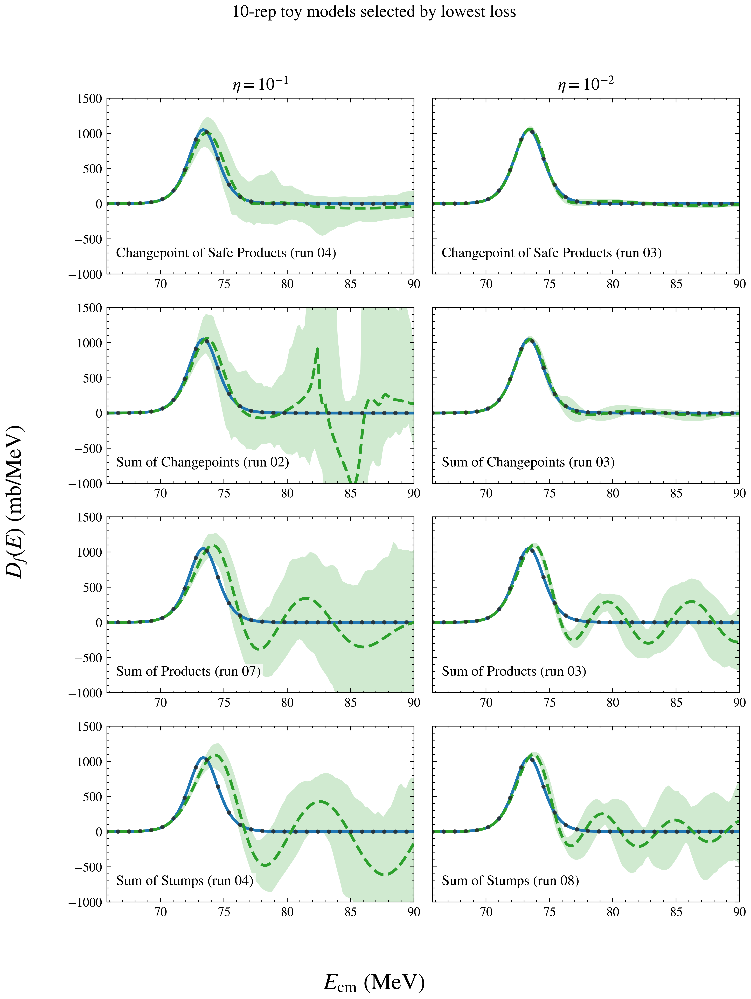

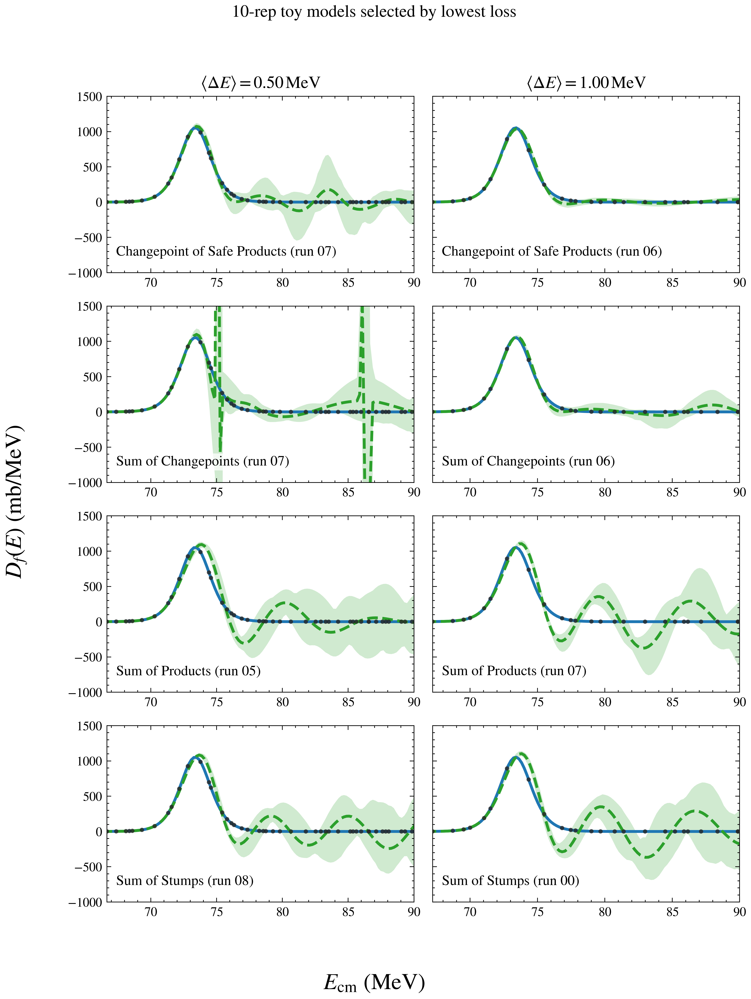

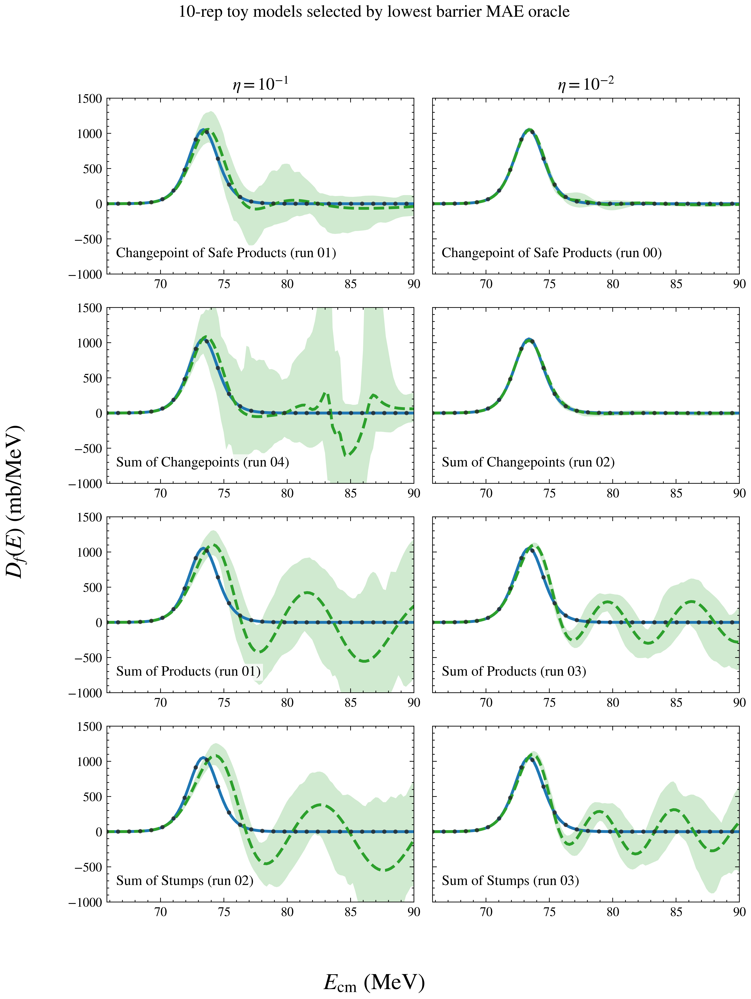

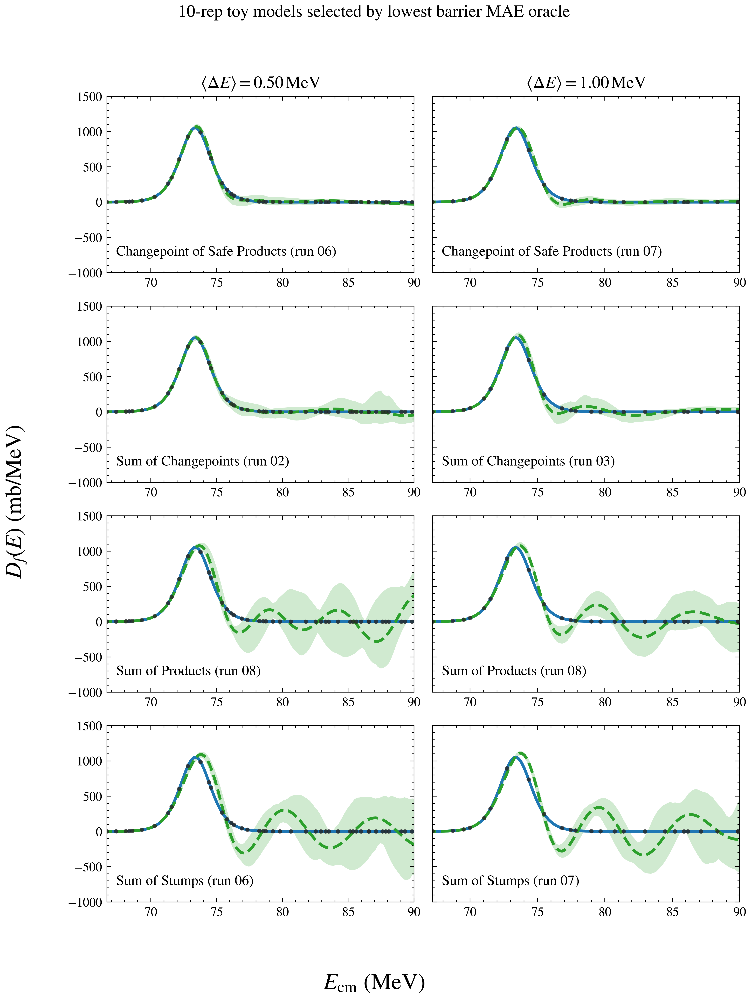

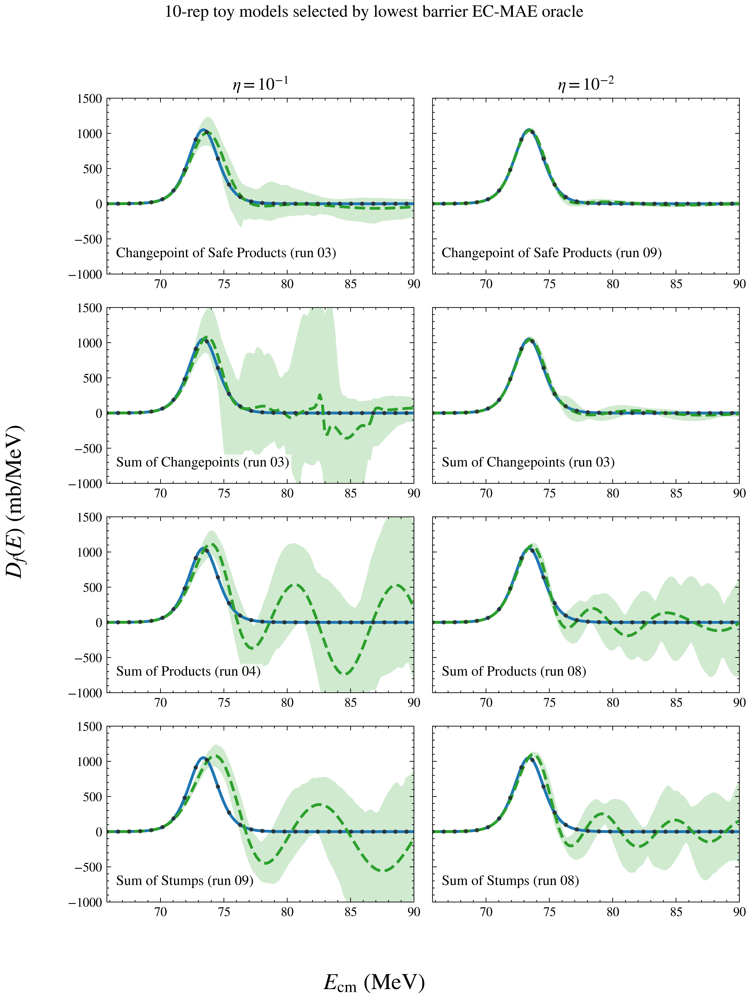

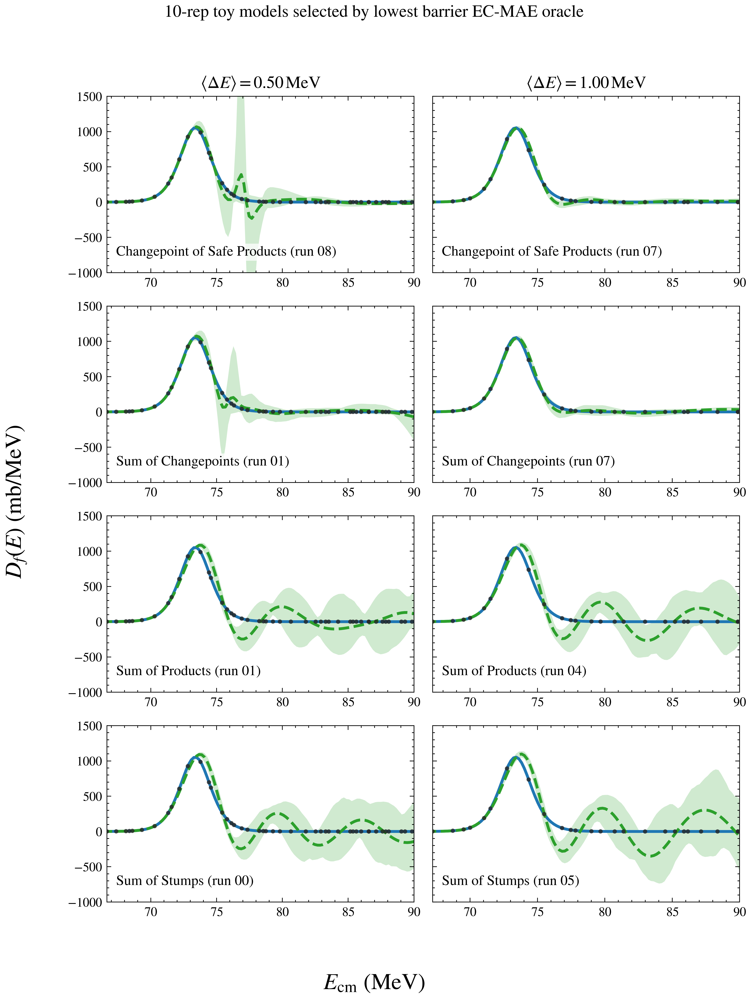

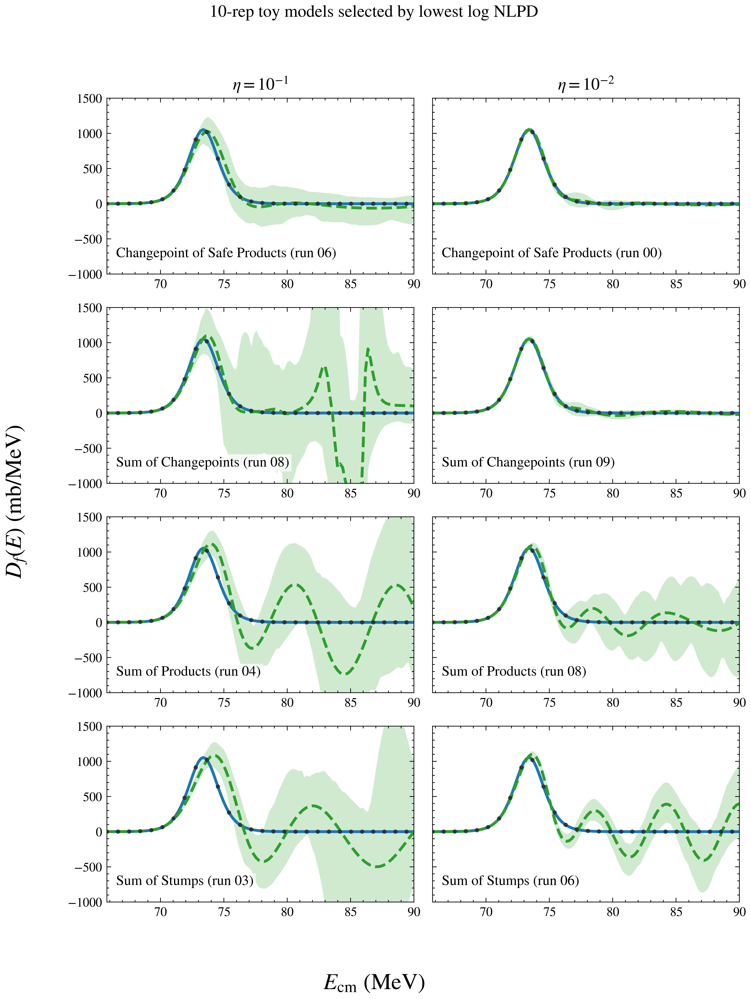

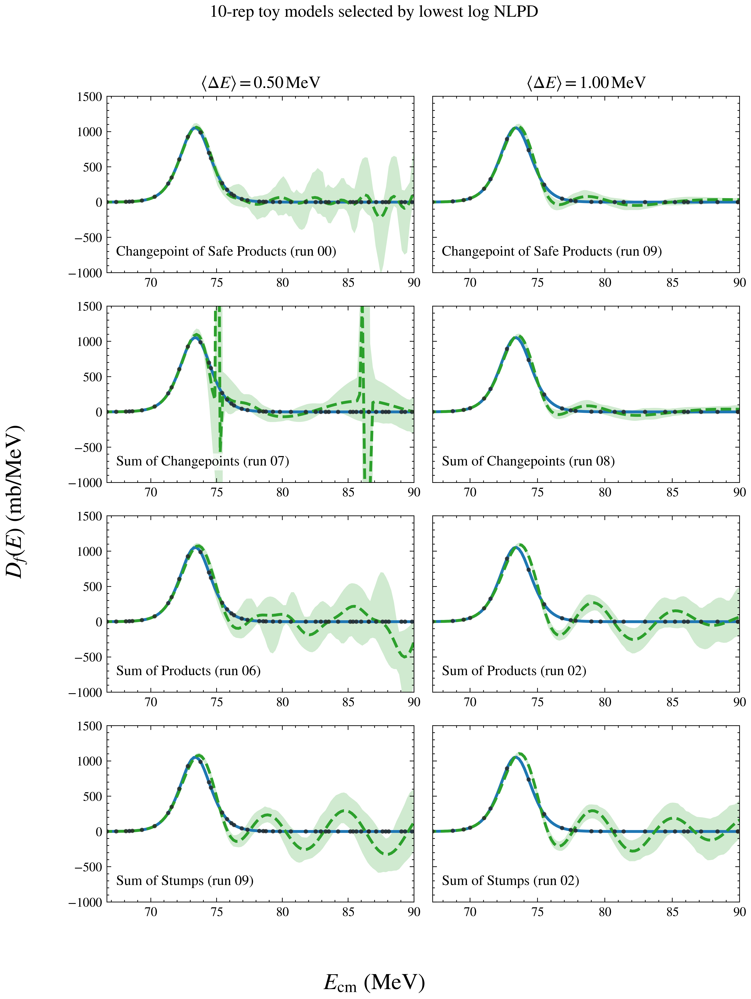

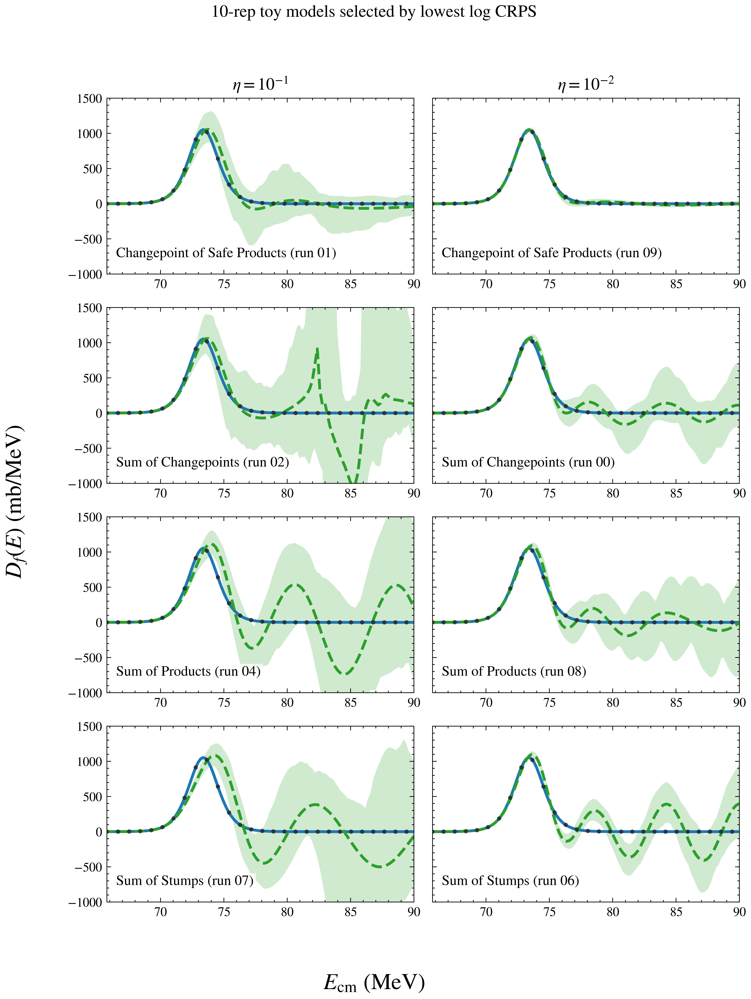

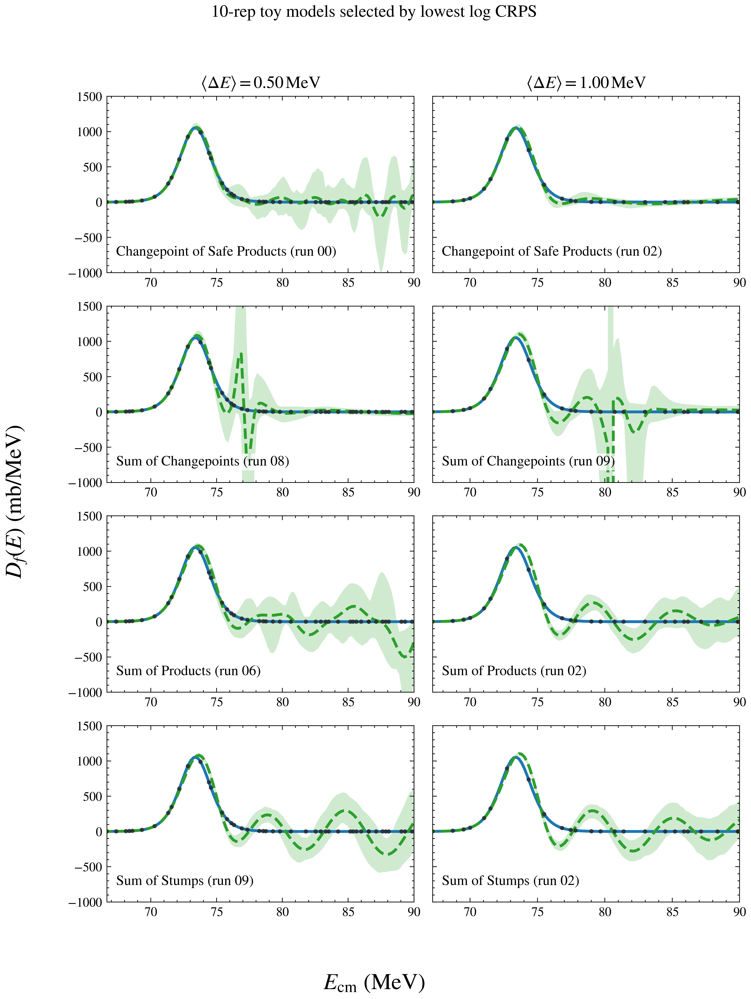

In [8]:
# Reproduce the final toy comparison grids, selecting among 10 runs different ways.
TRUE_COLOR = "tab:blue"
BNN_COLOR = "tab:green"
DATA_COLOR = "0.15"
BAND_ALPHA = 0.22


def add_panel_label(ax, label, loc="upper left"):
    if loc == "lower left":
        x, y, va = 0.03, 0.08, "bottom"
    else:
        x, y, va = 0.03, 0.92, "top"
    ax.text(
        x,
        y,
        label,
        transform=ax.transAxes,
        ha="left",
        va=va,
        fontsize=10,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=1.5),
    )


def load_selected_toy_case(case_slug, selector="min_total_train_loss"):
    preds = {}
    E_pred_by_model = {}
    true_barrier_by_model = {}
    E_train_by_model = {}
    selected_runs = {}

    for model_name, model_slug in MODEL_SPECS:
        candidates = bnn_10rep_metrics[
            (bnn_10rep_metrics["case_slug"] == case_slug)
            & (bnn_10rep_metrics["model_slug"] == model_slug)
        ]
        selected = candidates.loc[candidates[selector].idxmin()]
        selected_runs[model_name] = int(selected["run"])
        with h5py.File(selected["h5_path"], "r") as f:
            group = _only_h5_group(f)
            x_pred = group["x_pred"][()]
            preds[model_name] = group["d2_samples"][()]
            E_pred_by_model[model_name] = x_pred
            true_barrier_by_model[model_name] = true_barrier_from_group(group, x_pred)
            E_train_by_model[model_name] = group["E_data"][()]

    return {
        "folder": case_slug,
        "selector": selector,
        "E_pred_by_model": E_pred_by_model,
        "E_train_by_model": E_train_by_model,
        "true_barrier_by_model": true_barrier_by_model,
        "preds": preds,
        "selected_runs": selected_runs,
    }


def plot_toy_selection_comparison_grid(column_specs, outfile, suptitle=None, panel_label_loc="upper left"):
    nrows, ncols = len(MODEL_SPECS), len(column_specs)
    fig, axes = plt.subplots(nrows, ncols, figsize=(7.5, 2.45 * nrows), sharex=False, sharey=True)
    axes = np.asarray(axes).reshape(nrows, ncols)

    for col, (column_title, case) in enumerate(column_specs):
        axes[0, col].set_title(column_title, fontsize=12)
        for row, (model_name, _) in enumerate(MODEL_SPECS):
            ax = axes[row, col]
            E_pred = case["E_pred_by_model"][model_name]
            E_train = case["E_train_by_model"][model_name]
            true_d = case["true_barrier_by_model"][model_name]
            true_d_train = np.interp(E_train, E_pred, true_d)
            preds = case["preds"][model_name]
            d_mean = preds.mean(axis=0)
            d_low, d_high = np.percentile(preds, [2.5, 97.5], axis=0)

            ax.plot(E_pred, true_d, lw=2.0, color=TRUE_COLOR)
            ax.plot(E_pred, d_mean, lw=2.0, ls="--", color=BNN_COLOR)
            ax.fill_between(E_pred, d_low, d_high, color=BNN_COLOR, alpha=BAND_ALPHA, linewidth=0)
            ax.scatter(E_train, true_d_train, s=9, color=DATA_COLOR, alpha=0.8, edgecolor="none", zorder=5)
            add_panel_label(ax, f"{model_name} (run {case['selected_runs'][model_name]:02d})", loc=panel_label_loc)
            ax.set_xlim(E_train[0], 90)
            ax.set_ylim(-1000, 1500)
            ax.tick_params(labelsize=9)

    if suptitle:
        fig.suptitle(suptitle, fontsize=12, y=0.995)
    fig.supylabel(r"$D_f(E)$ (mb/MeV)", fontsize=16)
    fig.supxlabel(r"$E_{\mathrm{cm}}$ (MeV)", fontsize=16)
    fig.tight_layout(rect=[0.04, 0.04, 1, 0.965 if suptitle else 0.99])
    fig.savefig(outfile, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


SELECTOR_LABELS = {
    "min_total_train_loss": "lowest loss",
    "barrier_MAE": "lowest barrier MAE oracle",
    "barrier_emp_cov_MAE": "lowest barrier EC-MAE oracle",
    "nlpd_log": "lowest log NLPD",
    "crps_log": "lowest log CRPS",
}
SELECTOR_FILE_STEMS = {
    "min_total_train_loss": "selected_by_loss",
    "barrier_MAE": "selected_by_barrier_mae",
    "barrier_emp_cov_MAE": "selected_by_barrier_ec_mae",
    "nlpd_log": "selected_by_nlpd_log",
    "crps_log": "selected_by_crps_log",
}

for selector, selector_label in SELECTOR_LABELS.items():
    noise_case_1 = load_selected_toy_case("E_20_1e-1_log", selector=selector)
    noise_case_2 = load_selected_toy_case("E_20_1e-2_log", selector=selector)
    plot_toy_selection_comparison_grid(
        [
            (rf"$\eta = 10^{{-1}}$", noise_case_1),
            (rf"$\eta = 10^{{-2}}$", noise_case_2),
        ],
        PLOT_DIR / f"autobnn_10reps_noise_ratio_grid_log_{SELECTOR_FILE_STEMS[selector]}.png",
        suptitle=f"10-rep toy models selected by {selector_label}",
        panel_label_loc="lower left",
    )

    cv_case_1 = load_selected_toy_case("E_cv_05_log", selector=selector)
    cv_case_2 = load_selected_toy_case("E_cv_05_1MEV_log", selector=selector)
    plot_toy_selection_comparison_grid(
        [
            (rf"$\langle\Delta E\rangle = 0.50\,\mathrm{{MeV}}$", cv_case_1),
            (rf"$\langle\Delta E\rangle = 1.00\,\mathrm{{MeV}}$", cv_case_2),
        ],
        PLOT_DIR / f"autobnn_10reps_irregularity_spacing_grid_log_{SELECTOR_FILE_STEMS[selector]}.png",
        suptitle=f"10-rep toy models selected by {selector_label}",
        panel_label_loc="lower left",
    )


## Experimental D3 Sweep: Same Scoring Rules Without Ground Truth

The toy-data section tests the scoring rules against known Wong barriers. The experimental section below applies the same scoring functions to the D3 sweep over real fusion data. These scores can rank candidate runs, but unlike the toy case they do not have an exact true barrier to validate against.


In [9]:
# ============================================================
# configuration
# ============================================================

DE_STENCIL = 2

path_base = Path("/mnt/home/philipaa/scratch/barrier-paper-results/experiments8_d3_sweep")
save_dir = Path("../../plots")
save_dir.mkdir(parents=True, exist_ok=True)

plot_idx = 8

titles = (
    "16O208PbMorton1999",
    "40Ca40CaMontagnoli2012",
    "48Ca40CaJiang2010",
    "48Ca48CaStefanini2009",
)

d3_lambdas = ("0", "1e-6", "1e-4", "1e-2", "1e-1", "1", "1e2", "1e3")

ylims = {
    "16O208PbMorton1999": (-100, 1000),
    "40Ca40CaMontagnoli2012": (-100, 2000),
    "48Ca40CaJiang2010": (-100, 1000),
    "48Ca48CaStefanini2009": (-100, 1500),
}

metric_cols = [
    "redchi2_sigma",
    "nlpd_sigma",
    "crps_sigma",
    "cov95_sigma",
    "kl_sigma",
    "redchi2_log",
    "nlpd_log",
    "crps_log",
    "cov95_log",
    "kl_log",
    "redchi2_sigma_Ew",
    "nlpd_sigma_Ew",
    "crps_sigma_Ew",
    "cov95_sigma_Ew",
    "kl_sigma_Ew",
]

rows = []
missing = []


# ============================================================
# smarter d3_lambda sweep analysis
# ============================================================

import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
from pathlib import Path


# ============================================================
# helpers
# ============================================================

def h5_path_for(title, lam):
    return path_base / (
        f"experiments_{title}_bnn_soc_d3lam_{lam}.h5_8x1000_"
        f"lognormal_soc_d3lam_{lam}"
    )


def group_name_for(dataset_idx, run_idx):
    return f"{dataset_idx:05d}_run{run_idx:02d}"


def collect_d3_sweep_metrics():
    rows = []
    missing = []

    for lam in d3_lambdas:
        for dataset_idx, title in enumerate(titles):
            h5_path = h5_path_for(title, lam)

            if not h5_path.exists():
                missing.append({
                    "dataset_idx": dataset_idx,
                    "dataset": title,
                    "d3_lambda": lam,
                    "run_idx": None,
                    "group_name": None,
                    "reason": "missing_file",
                    "path": str(h5_path),
                })
                continue

            with h5py.File(h5_path, "r") as f:
                for run_idx in range(10):
                    group_name = group_name_for(dataset_idx, run_idx)

                    if group_name not in f:
                        missing.append({
                            "dataset_idx": dataset_idx,
                            "dataset": title,
                            "d3_lambda": lam,
                            "run_idx": run_idx,
                            "group_name": group_name,
                            "reason": "missing_group",
                            "path": str(h5_path),
                        })
                        continue

                    grp = f[group_name]

                    x = grp["x_pred"][:]
                    y_samples = grp["y_samples"][:]
                    E_data = grp["E_data"][:]
                    Sigma_data = grp["Sigma_data"][:]
                    Sigma_err = grp["Sigma_err"][:]

                    if "d2_samples" not in grp:
                        missing.append({
                            "dataset_idx": dataset_idx,
                            "dataset": title,
                            "d3_lambda": lam,
                            "run_idx": run_idx,
                            "group_name": group_name,
                            "reason": "missing_d2_samples",
                            "path": str(h5_path),
                        })
                        continue

                    y_samples_at_data = np.vstack([
                        np.interp(E_data, x, y_samples[i])
                        for i in range(y_samples.shape[0])
                    ])

                    metrics = compute_metric_bundle(
                        E_data=E_data,
                        Sigma_data=Sigma_data,
                        Sigma_err=Sigma_err,
                        y_samples_at_data=y_samples_at_data,
                    )

                    row = {
                        "dataset_idx": dataset_idx,
                        "dataset": title,
                        "d3_lambda": lam,
                        "d3_lambda_value": float(lam),
                        "run_idx": run_idx,
                        "group_name": group_name,
                        "h5_path": str(h5_path),
                    }
                    row.update(metrics)
                    rows.append(row)

    metrics_df = pd.DataFrame(rows)
    missing_df = pd.DataFrame(missing)

    if metrics_df.empty:
        raise RuntimeError(f"No run groups were loaded from {path_base}")

    return metrics_df, missing_df


def save_metric_tables(metrics_df, missing_df):
    csv_path = save_dir / "bnn_fit_quality_metrics_d3_sweep.csv"
    pkl_path = save_dir / "bnn_fit_quality_metrics_d3_sweep.pkl"
    missing_csv_path = save_dir / "bnn_fit_quality_missing_d3_sweep.csv"
    summary_csv = save_dir / "bnn_fit_quality_best_runs_d3_sweep.csv"

    metrics_df.to_csv(csv_path, index=False)
    metrics_df.to_pickle(pkl_path)
    missing_df.to_csv(missing_csv_path, index=False)

    print("\nSaved metrics dataframe to:")
    print(csv_path)
    print(pkl_path)

    if missing_df.empty:
        print("\nNo missing files or groups.")
    else:
        print(f"\nMissing files/groups: {len(missing_df)}")
        print(missing_df[["dataset", "d3_lambda", "run_idx", "reason"]].to_string(index=False))

    summary_rows = []

    print("\n" + "=" * 80)
    print("BEST RUN INDEX PER DATASET/LAMBDA FOR EACH METRIC")
    print("=" * 80)

    for metric in metric_cols:
        print(f"\nMetric: {metric}")

        for (title, lam), df_sub in metrics_df.groupby(["dataset", "d3_lambda"], sort=False):
            if df_sub[metric].notna().sum() == 0:
                continue

            best_row = df_sub.loc[df_sub[metric].idxmin()]

            print(
                f"  {title:28s} d3_lambda={lam:>4s} -> run_idx = {int(best_row['run_idx']):2d} "
                f"(score = {best_row[metric]:.6g})"
            )

            summary_rows.append({
                "metric": metric,
                "dataset": title,
                "d3_lambda": lam,
                "d3_lambda_value": float(lam),
                "best_run_idx": int(best_row["run_idx"]),
                "best_score": best_row[metric],
            })

    best_summary_df = pd.DataFrame(summary_rows)
    best_summary_df.to_csv(summary_csv, index=False)

    print("\nSaved best-run summary to:")
    print(summary_csv)

    return best_summary_df


def plot_metric_heatmap(metrics_df, metric, save_dir=None, log_color=False):
    df = metrics_df.copy()
    df["d3_lambda"] = pd.Categorical(
        df["d3_lambda"],
        categories=d3_lambdas,
        ordered=True,
    )

    pivot = (
        df.groupby(["dataset", "d3_lambda"], observed=False)[metric]
        .median()
        .unstack("d3_lambda")
        .reindex(index=list(titles), columns=list(d3_lambdas))
    )

    values = pivot.values.astype(float)

    if log_color:
        with np.errstate(divide="ignore", invalid="ignore"):
            plot_values = np.log10(values)
    else:
        plot_values = values

    fig, ax = plt.subplots(figsize=(9.5, 3.8))

    im = ax.imshow(plot_values, aspect="auto", origin="upper")

    ax.set_xticks(np.arange(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns, rotation=45, ha="right")
    ax.set_yticks(np.arange(len(pivot.index)))
    ax.set_yticklabels(pivot.index)

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(
        rf"$\log_{{10}}$ median {metric}" if log_color else f"median {metric}"
    )

    finite_plot_vals = plot_values[np.isfinite(plot_values)]
    threshold = np.nanmedian(finite_plot_vals) if finite_plot_vals.size else 0.0

    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            val = pivot.iloc[i, j]
            zval = plot_values[i, j]

            if np.isfinite(val):
                ax.text(
                    j,
                    i,
                    f"{val:.2g}",
                    ha="center",
                    va="center",
                    fontsize=8,
                    color="white" if np.isfinite(zval) and zval > threshold else "black",
                )

    ax.set_title(f"Median {metric} over 10 runs")
    ax.set_xlabel(r"$\lambda_{d3}$")
    ax.set_ylabel("Dataset")

    fig.tight_layout()

    if save_dir is not None:
        out = Path(save_dir) / f"heatmap_median_{metric}.png"
        fig.savefig(out, dpi=300, bbox_inches="tight")
        print(f"Saved {out}")

    plt.show()
    plt.close(fig)


def representative_run_indices(metrics_df, dataset, lam, metric="crps_sigma"):
    sub = metrics_df[
        (metrics_df["dataset"] == dataset)
        & (metrics_df["d3_lambda"] == lam)
    ].copy()

    sub = sub[np.isfinite(sub[metric])]
    sub = sub.sort_values(metric)

    if sub.empty:
        return {}

    best = int(sub.iloc[0]["run_idx"])
    median = int(sub.iloc[len(sub) // 2]["run_idx"])
    worst = int(sub.iloc[-1]["run_idx"])

    return {
        "best": best,
        "median": median,
        "worst": worst,
    }


def plot_lambda_sweep_representatives(metrics_df, title, metric="crps_sigma"):
    fig, ax = plt.subplots(figsize=(7.2, 4.6))

    cmap = plt.cm.viridis
    plotted = 0

    for lam_idx, lam in enumerate(d3_lambdas):
        reps = representative_run_indices(metrics_df, title, lam, metric=metric)
        if not reps:
            continue

        run_idx = reps["median"]
        h5_path = h5_path_for(title, lam)

        if not h5_path.exists():
            continue

        dataset_idx = list(titles).index(title)
        group_name = group_name_for(dataset_idx, run_idx)

        with h5py.File(h5_path, "r") as f:
            if group_name not in f:
                continue

            grp = f[group_name]
            x = grp["x_pred"][:]
            E_data = grp["E_data"][:]
            D_samples = grp["d2_samples"][:]
            D_mean = D_samples.mean(axis=0)

        color = cmap(lam_idx / max(len(d3_lambdas) - 1, 1))

        ax.plot(
            x,
            D_mean,
            lw=1.8,
            color=color,
            label=rf"$\lambda_{{d3}}={lam}$",
        )
        plotted += 1

    if plotted == 0:
        plt.close(fig)
        print(f"No lambda sweep plotted for {title}")
        return

    ax.set_title(f"{title}: median run per lambda")
    ax.set_xlabel(r"$E_{\rm c.m.}$ (MeV)")
    ax.set_ylabel(r"$D_f(E)$ (mb/MeV)")
    ax.set_ylim(ylims[title])
    ax.grid(True, alpha=0.25)
    ax.legend(frameon=False, fontsize=8, ncol=2)

    fig.tight_layout()

    out = save_dir / f"lambda_sweep_median_runs_{title}_{metric}.png"
    fig.savefig(out, dpi=300, bbox_inches="tight")
    print(f"Saved {out}")

    plt.show()
    plt.close(fig)


def plot_representative_runs(metrics_df, title, lam, metric="crps_sigma"):
    reps = representative_run_indices(metrics_df, title, lam, metric=metric)

    if not reps:
        print(f"No runs for {title}, lambda={lam}")
        return

    h5_path = h5_path_for(title, lam)

    if not h5_path.exists():
        print(f"Missing file: {h5_path}")
        return

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(12, 3.6),
        sharex=True,
        sharey=True,
    )

    dataset_idx = list(titles).index(title)

    with h5py.File(h5_path, "r") as f:
        for ax, (rep_name, run_idx) in zip(axes, reps.items()):
            group_name = group_name_for(dataset_idx, run_idx)

            if group_name not in f:
                ax.set_visible(False)
                continue

            grp = f[group_name]

            x = grp["x_pred"][:]
            E_data = grp["E_data"][:]
            D_samples = grp["d2_samples"][:]
            D_mean = D_samples.mean(axis=0)

            bands = percentile_bands(D_samples, levels=(0.68,))

            score = metrics_df[
                (metrics_df["dataset"] == title)
                & (metrics_df["d3_lambda"] == lam)
                & (metrics_df["run_idx"] == run_idx)
            ][metric].iloc[0]

            ax.plot(x, D_mean, color="tab:red", ls="--", lw=2.0)
            ax.fill_between(
                x,
                bands["lower_68"],
                bands["upper_68"],
                color="tab:red",
                alpha=0.18,
                linewidth=0,
            )

            ax.set_title(f"{rep_name}: run {run_idx:02d}\n{metric}={score:.3g}")
            ax.set_xlim(E_data.min(), E_data.max())
            ax.set_ylim(ylims[title])
            ax.grid(True, alpha=0.25)

    fig.suptitle(rf"{title}, $\lambda_{{d3}}={lam}$", y=1.04)
    fig.supxlabel(r"$E_{\rm c.m.}$ (MeV)")
    fig.supylabel(r"$D_f(E)$ (mb/MeV)")

    fig.tight_layout()

    out = save_dir / f"representative_{title}_d3lam_{lam}_{metric}.png"
    fig.savefig(out, dpi=300, bbox_inches="tight")
    print(f"Saved {out}")

    plt.show()
    plt.close(fig)


Saved metrics dataframe to:
../../plots/bnn_fit_quality_metrics_d3_sweep.csv
../../plots/bnn_fit_quality_metrics_d3_sweep.pkl

Missing files/groups: 29
              dataset d3_lambda  run_idx        reason
   16O208PbMorton1999      1e-4        0 missing_group
   16O208PbMorton1999      1e-4        1 missing_group
   16O208PbMorton1999      1e-4        2 missing_group
   16O208PbMorton1999      1e-4        3 missing_group
   16O208PbMorton1999      1e-4        4 missing_group
   16O208PbMorton1999      1e-4        5 missing_group
   16O208PbMorton1999      1e-4        8 missing_group
   16O208PbMorton1999      1e-4        9 missing_group
   16O208PbMorton1999      1e-1        0 missing_group
   16O208PbMorton1999      1e-1        1 missing_group
   16O208PbMorton1999      1e-1        2 missing_group
   16O208PbMorton1999      1e-1        7 missing_group
   16O208PbMorton1999      1e-1        8 missing_group
    48Ca40CaJiang2010      1e-1        8 missing_group
48Ca48CaStefanini2009 

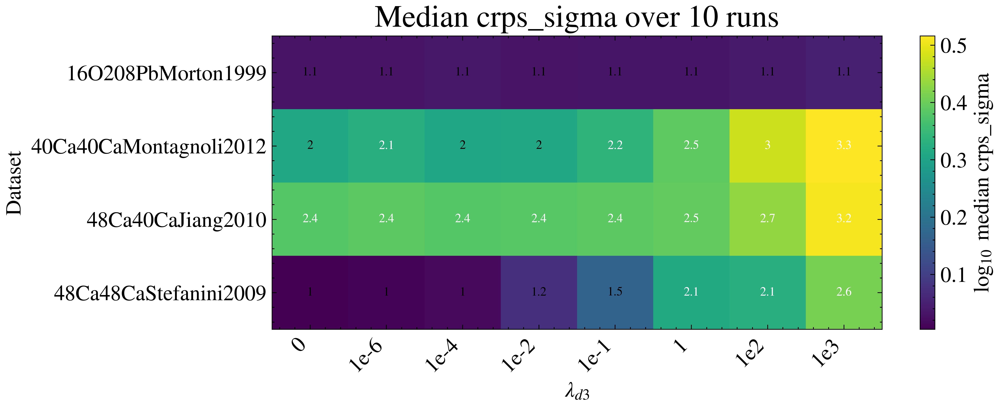

Saved ../../plots/heatmap_median_nlpd_sigma.png


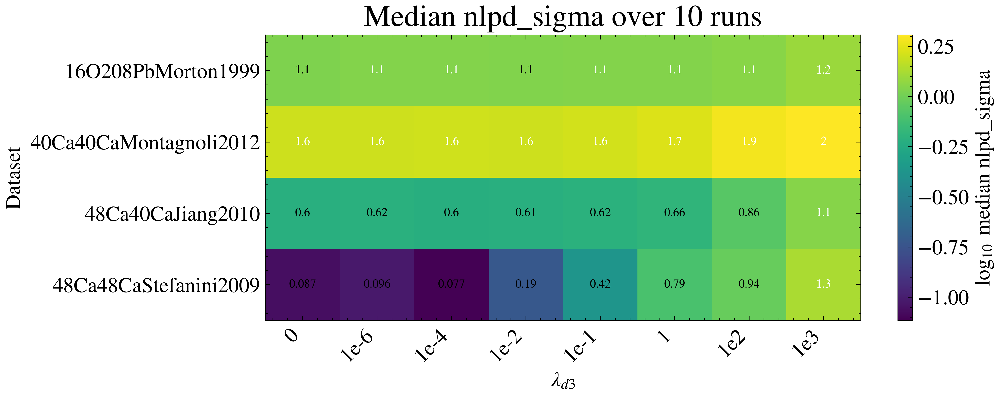

Saved ../../plots/heatmap_median_redchi2_sigma.png


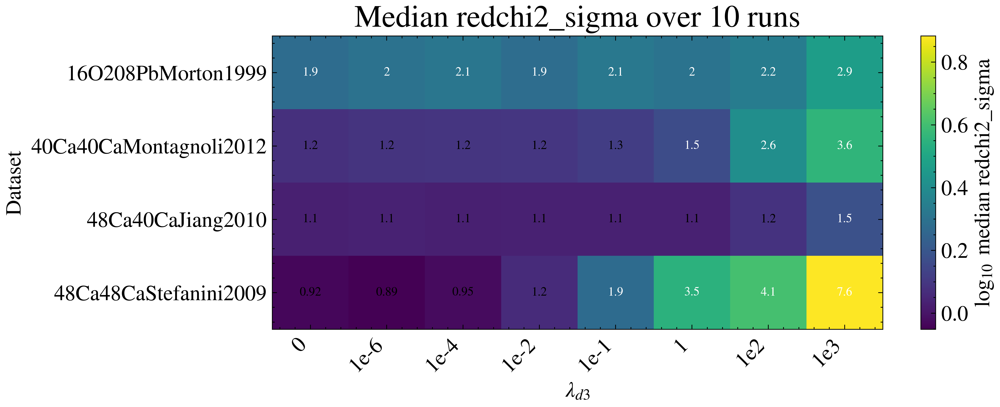

Saved ../../plots/heatmap_median_cov95_sigma.png


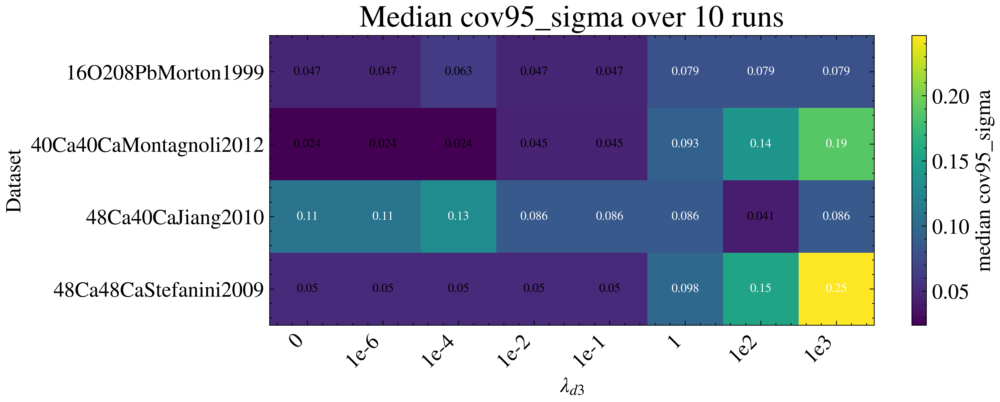

Saved ../../plots/heatmap_median_kl_sigma.png


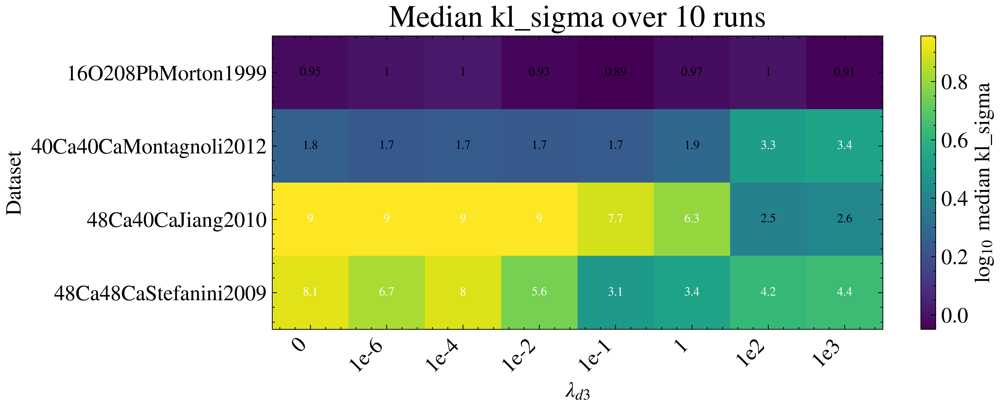

In [10]:
# ============================================================
# run analysis
# ============================================================

metrics_df, missing_df = collect_d3_sweep_metrics()
best_summary_df = save_metric_tables(metrics_df, missing_df)

primary_metrics = [
    "crps_sigma",
    "nlpd_sigma",
    "redchi2_sigma",
    "cov95_sigma",
    "kl_sigma",
]

for metric in primary_metrics:
    plot_metric_heatmap(
        metrics_df,
        metric,
        save_dir=save_dir,
        log_color=metric not in {"cov95_sigma"},
    )


In [11]:
"""
# ============================================================
# main loop
# ============================================================

for lam in d3_lambdas:
    for idx, title in enumerate(titles):
        h5_path = path_base / f"experiments_{title}_bnn_soc_d3lam_{lam}.h5_8x1000_lognormal_soc_d3lam_{lam}"

        if not h5_path.exists():
            missing.append({
                "dataset_idx": idx,
                "dataset": title,
                "d3_lambda": lam,
                "run_idx": None,
                "group_name": None,
                "reason": "missing_file",
                "path": str(h5_path),
            })
            continue

        fig, axes = plt.subplots(2, 5, figsize=(22, 8))
        axes = axes.ravel()

        with h5py.File(h5_path, "r") as f:
            for sub_idx in range(10):
                ax = axes[sub_idx]
                group_name = f"{idx:05d}_run{sub_idx:02d}"

                if group_name not in f:
                    ax.set_visible(False)
                    missing.append({
                        "dataset_idx": idx,
                        "dataset": title,
                        "d3_lambda": lam,
                        "run_idx": sub_idx,
                        "group_name": group_name,
                        "reason": "missing_group",
                        "path": str(h5_path),
                    })
                    continue

                grp = f[group_name]
                x = grp["x_pred"][:]
                y_mean = grp["y_mean"][:]
                y_samples = grp["y_samples"][:]
                E_data = grp["E_data"][:]
                Sigma_data = grp["Sigma_data"][:]
                Sigma_err = grp["Sigma_err"][:]

                if "d2_samples" in grp:
                    D_samples = grp["d2_samples"][:]
                    D_mean = D_samples.mean(axis=0)
                else:
                    raise KeyError(
                        f"{group_name} in {h5_path} is missing d2_samples; "
                        "the old fallback required project-local training code."
                    )

                y_samples_at_data = np.vstack([
                    np.interp(E_data, x, y_samples[i]) for i in range(y_samples.shape[0])
                ])

                metrics = compute_metric_bundle(
                    E_data=E_data,
                    Sigma_data=Sigma_data,
                    Sigma_err=Sigma_err,
                    y_samples_at_data=y_samples_at_data,
                )

                row = {
                    "dataset_idx": idx,
                    "dataset": title,
                    "d3_lambda": lam,
                    "d3_lambda_value": float(lam),
                    "run_idx": sub_idx,
                    "group_name": group_name,
                    "h5_path": str(h5_path),
                }
                row.update(metrics)
                rows.append(row)

                ax.plot(x, D_mean, "--r", linewidth=1.6)

                bands = percentile_bands(D_samples, levels=(0.68,))
                ax.fill_between(
                    x,
                    bands["lower_68"],
                    bands["upper_68"],
                    color="red",
                    alpha=0.15,
                )

                ax.set_xlim(E_data.min(), E_data.max())
                ax.set_ylim(ylims[title])
                ax.set_title(f"run {sub_idx:02d}", fontsize=11)
                ax.grid(True, alpha=0.25)

                ax.text(
                    0.02,
                    0.98,
                    f"mean KL = {metrics['kl_sigma']:.3f}",
                    transform=ax.transAxes,
                    ha="left",
                    va="top",
                    fontsize=10,
                    bbox=dict(
                        boxstyle="round,pad=0.25",
                        facecolor="white",
                        alpha=0.85,
                        edgecolor="none",
                    ),
                )

                ax.text(
                    0.98,
                    0.98,
                    f"mean CRPS = {metrics['crps_sigma']:.3f}",
                    transform=ax.transAxes,
                    ha="right",
                    va="top",
                    fontsize=10,
                    bbox=dict(
                        boxstyle="round,pad=0.25",
                        facecolor="white",
                        alpha=0.85,
                        edgecolor="none",
                    ),
                )

        fig.suptitle(f"{title}, d3_lambda={lam}", fontsize=18)
        plt.tight_layout(rect=[0, 0, 1, 0.95])
        out_png = save_dir / f"barrier_runs_{title}_d3lam_{lam}.png"
        # fig.savefig(out_png, dpi=300)
        plt.show()

# ============================================================
# make dataframe and save
# ============================================================

metrics_df = pd.DataFrame(rows)
missing_df = pd.DataFrame(missing)

csv_path = save_dir / "bnn_fit_quality_metrics_d3_sweep.csv"
pkl_path = save_dir / "bnn_fit_quality_metrics_d3_sweep.pkl"
missing_csv_path = save_dir / "bnn_fit_quality_missing_d3_sweep.csv"
summary_csv = save_dir / "bnn_fit_quality_best_runs_d3_sweep.csv"

if metrics_df.empty:
    raise RuntimeError(f"No run groups were loaded from {path_base}")

metrics_df.to_csv(csv_path, index=False)
metrics_df.to_pickle(pkl_path)
missing_df.to_csv(missing_csv_path, index=False)

print("\nSaved metrics dataframe to:")
print(csv_path)
print(pkl_path)

if missing_df.empty:
    print("\nNo missing files or groups.")
else:
    print(f"\nMissing files/groups: {len(missing_df)}")
    print(missing_df[["dataset", "d3_lambda", "run_idx", "reason"]].to_string(index=False))

print("\nMetrics dataframe:")
print(metrics_df)

# ============================================================
# print best run per dataset/lambda for each metric
# ============================================================

print("\n" + "=" * 80)
print("BEST RUN INDEX PER DATASET/LAMBDA FOR EACH METRIC")
print("=" * 80)

summary_rows = []
for metric in metric_cols:
    print(f"\nMetric: {metric}")
    for (title, lam), df_sub in metrics_df.groupby(["dataset", "d3_lambda"], sort=False):
        best_row = df_sub.loc[df_sub[metric].idxmin()]
        print(
            f"  {title:28s} d3_lambda={lam:>4s} -> run_idx = {int(best_row['run_idx']):2d} "
            f"(score = {best_row[metric]:.6g})"
        )
        summary_rows.append({
            "metric": metric,
            "dataset": title,
            "d3_lambda": lam,
            "d3_lambda_value": float(lam),
            "best_run_idx": int(best_row["run_idx"]),
            "best_score": best_row[metric],
        })

best_summary_df = pd.DataFrame(summary_rows)
best_summary_df.to_csv(summary_csv, index=False)

print("\nSaved best-run summary to:")
print(summary_csv)
print(best_summary_df)
"""

'\n# ============================================================\n# main loop\n# ============================================================\n\nfor lam in d3_lambdas:\n    for idx, title in enumerate(titles):\n        h5_path = path_base / f"experiments_{title}_bnn_soc_d3lam_{lam}.h5_8x1000_lognormal_soc_d3lam_{lam}"\n\n        if not h5_path.exists():\n            missing.append({\n                "dataset_idx": idx,\n                "dataset": title,\n                "d3_lambda": lam,\n                "run_idx": None,\n                "group_name": None,\n                "reason": "missing_file",\n                "path": str(h5_path),\n            })\n            continue\n\n        fig, axes = plt.subplots(2, 5, figsize=(22, 8))\n        axes = axes.ravel()\n\n        with h5py.File(h5_path, "r") as f:\n            for sub_idx in range(10):\n                ax = axes[sub_idx]\n                group_name = f"{idx:05d}_run{sub_idx:02d}"\n\n                if group_name not in f:\n  